Draw the main publication figures from the analysis tables produced by NB01–NB09.


In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def _build_data_tools():
    import json
    import os
    import re
    import unicodedata
    import warnings
    import numpy as np
    import pandas as pd
    from scipy import stats
    warnings.filterwarnings('ignore')

    def path_join(*parts):
        return os.path.normpath(os.path.join(*parts))

    def normalize_newlines(frame):
        for column in frame.select_dtypes(include=['object', 'string']).columns:
            frame[column] = frame[column].map(lambda value: value.replace('\r\n', '\n').replace('\r', '\n') if isinstance(value, str) else value)
        return frame
    from pathlib import Path
    _start = Path.cwd().resolve()
    _repo = next((p for p in (_start, *_start.parents) if (p / 'experiments/clinical_protocols').is_dir() and (p / 'data').is_dir()), None)
    if _repo is None:
        raise FileNotFoundError('Run the notebook from inside the repository.')
    if os.name == 'nt' and (not str(_repo).startswith(chr(92) * 2 + '?' + chr(92))):
        _repo = Path(chr(92) * 2 + '?' + chr(92) + str(_repo))
    GOLD = str(_repo)
    PAPER = str(_repo / 'results/clinical_evaluation')
    HERE = str(_repo / 'analyses/clinical_evaluation')
    ALPHA = GOLD
    RESEARCH = GOLD
    TABLES = path_join(PAPER, 'tables')
    FIGURES = path_join(PAPER, 'figures')
    os.makedirs(TABLES, exist_ok=True)
    os.makedirs(FIGURES, exist_ok=True)
    DATASET = str(_repo / 'data' / 'limfmed_dataset_gold.csv')
    PBASE = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_complete'
    PBASE_NON = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_truncated'
    ORG_DS = 'experiments/clinical_protocols/delphi_panels/heterogeneous_deepseek_organizer_complete'
    ORG_QWEN = 'experiments/clinical_protocols/delphi_panels/heterogeneous_qwen_organizer_complete'
    ORG_GEM = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gemini_external_organizer'
    PWEAK = 'experiments/clinical_protocols/delphi_panels/panel_qwen_organizer_gemini_deepseek_pro'
    PMIXED = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_gemini_glm'
    PSTRONG = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_glm_gpt120'
    HOMOG = {'gpt': 'experiments/homogeneous_panels/three_gpt_members', 'qwen': 'experiments/homogeneous_panels/three_qwen_members', 'deepseekv4': 'experiments/homogeneous_panels/three_deepseekv4_members_complete', 'gemini': 'experiments/homogeneous_panels/three_gemini_members'}
    FIX_PBASE = 'experiments/fixed_length_controls/delphi_panels/internal_panel_variants/standard_protocol/heterogeneous_gpt120_organizer'
    SINGLES = ['gpt', 'qwen', 'deepseekv4', 'deepseekv4pro', 'gemini', 'glm', 'kimi']
    MODEL_NAME = {'gpt': 'gpt-oss-120b', 'qwen': 'qwen3-235b-a22b', 'deepseekv4': 'deepseek-v4-flash', 'deepseekv4pro': 'deepseek-v4-pro', 'gemini': 'gemini-3.7-flash', 'glm': 'glm-5.2', 'kimi': 'kimi'}
    PANELS = {'P-base': (PBASE, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gpt', True), 'P-base/org-ds': (ORG_DS, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'deepseekv4', True), 'P-base/org-qwen': (ORG_QWEN, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'qwen', True), 'P-base/org-gemini': (ORG_GEM, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gemini', False), 'P-weak': (PWEAK, 'delphi_pweak_{d}_judge.csv', ['qwen', 'gemini', 'deepseekv4pro'], 'qwen', True), 'P-mixed': (PMIXED, 'delphi_pmixed_{d}_judge.csv', ['deepseekv4', 'gemini', 'glm'], 'deepseekv4', True), 'P-strong': (PSTRONG, 'delphi_pstrong_{d}_judge.csv', ['deepseekv4', 'glm', 'gpt'], 'deepseekv4', True), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_{d}_judge.csv', ['gpt'] * 3, 'gpt', True), 'homog qwen': (HOMOG['qwen'], 'delphi_homog_qwen_{d}_judge.csv', ['qwen'] * 3, 'qwen', True), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_{d}_judge.csv', ['deepseekv4'] * 3, 'deepseekv4', True), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_{d}_judge.csv', ['gemini'] * 3, 'gemini', True)}
    HETERO = ['P-base', 'P-weak', 'P-mixed', 'P-strong']
    HOMOGS = ['homog gpt', 'homog qwen', 'homog deepseekv4', 'homog gemini']
    ORGANIZER_ARMS = ['P-base', 'P-base/org-ds', 'P-base/org-qwen', 'P-base/org-gemini']
    RAW_RUN = {'P-base': PBASE + '/delphi_noroles.csv', 'P-base/org-ds': ORG_DS + '/delphi_noroles.csv', 'P-base/org-qwen': ORG_QWEN + '/delphi_noroles.csv', 'P-base/org-gemini': ORG_GEM + '/delphi_noroles.csv', 'P-weak': PWEAK + '/delphi_pweak_noroles.csv', 'P-mixed': PMIXED + '/delphi_pmixed_noroles.csv', 'P-strong': PSTRONG + '/delphi_pstrong_noroles.csv', 'homog gpt': HOMOG['gpt'] + '/delphi_homog_gpt_noroles.csv', 'homog qwen': HOMOG['qwen'] + '/delphi_homog_qwen_noroles.csv', 'homog deepseekv4': HOMOG['deepseekv4'] + '/delphi_homog_deepseekv4_noroles.csv', 'homog gemini': HOMOG['gemini'] + '/delphi_homog_gemini_noroles.csv'}
    ROUNDS_EVAL = {'P-base': (PBASE, 'delphi_base_noroles_protocol_r{r}_judge.csv'), 'P-weak': (PWEAK, 'delphi_pweak_noroles_protocol_r{r}_judge.csv'), 'P-mixed': (PMIXED, 'delphi_pmixed_noroles_protocol_r{r}_judge.csv'), 'P-strong': (PSTRONG, 'delphi_pstrong_noroles_protocol_r{r}_judge.csv'), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_noroles_protocol_r{r}_judge.csv'), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_noroles_protocol_r{r}_judge.csv'), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_noroles_protocol_r{r}_judge.csv')}

    def baseline_path(model, design='noroles', variant='nofix'):
        return f"experiments/{('clinical_protocols' if variant == 'nofix' else 'fixed_length_controls')}/single_model_baselines/baseline_{model}/llm_as_judge/baseline_{design}_{model}_judge.csv"

    def panel_path(name, design='noroles'):
        d, f, *_ = PANELS[name]
        return d + '/llm_as_judge/' + f.format(d=design)

    def _abs(rel):
        return rel if os.path.isabs(rel) else path_join(GOLD, rel)

    def read_csv(rel, filter_result=True):
        p = _abs(rel)
        if not os.path.exists(p):
            return None
        d = normalize_newlines(pd.read_csv(p, sep=';', encoding='utf-8-sig', low_memory=False))
        d.columns = [c.lstrip('\ufeff') for c in d.columns]
        if filter_result and 'table_source' in d.columns:
            d = d[d['table_source'].fillna('result_df') == 'result_df']
        return d

    def read_judge(rel):
        d = read_csv(rel)
        if d is None or 'Judge_score' not in d.columns:
            return None
        d = d.dropna(subset=['Judge_score', 'Vignette']).drop_duplicates('Vignette', keep='first')
        d['Judge_score'] = pd.to_numeric(d['Judge_score'], errors='coerce')
        return d.set_index('Vignette')

    def load_main_arms(design='noroles', include_usc=False):
        arms = {}
        for m in SINGLES:
            d = read_judge(baseline_path(m, design))
            if d is not None:
                arms[m] = d
        for name in PANELS:
            d = read_judge(panel_path(name, design))
            if d is not None:
                arms[name] = d
        if include_usc and design == 'noroles':
            for k in (3, 5, 7):
                d = read_judge(f'experiments/token_budget_controls/universal_self_consistency_gpt_seven_samples/llm_as_judge/usc_gpt_sc{k}_judge.csv')
                if d is not None:
                    arms[f'USC@{k} gpt'] = d
        return arms

    def score(arms, name):
        return arms[name]['Judge_score'].astype(float)

    def dataset():
        d = normalize_newlines(pd.read_csv(DATASET, sep=None, engine='python'))
        return d

    def protocol_text(d):
        for c in ('winner_protocol', 'baseline_protocol_anonymous', 'baseline_protocol'):
            if c in d.columns:
                return d[c].astype(str)
        raise KeyError('no protocol column')

    def strip_author(text):
        if not isinstance(text, str):
            return ''
        return re.split('(?im)^\\s*Protocol Author\\s*:', text, maxsplit=1)[0].rstrip()

    def n_words(text):
        return len(re.findall('\\S+', strip_author(text))) if isinstance(text, str) else np.nan

    def items(d):
        rows = []
        for v, s in d['judge_details'].dropna().items():
            try:
                arr = json.loads(s)
            except Exception:
                continue
            for it in arr:
                ax = next((t.split(':', 1)[1] for t in it.get('tags') or [] if isinstance(t, str) and t.startswith('axis:')), None)
                rows.append((v, int(it['id']), int(it.get('points', 0) or 0), ax, bool(it.get('met'))))
        return pd.DataFrame(rows, columns=['Vignette', 'cid', 'points', 'axis', 'met'])

    def item_matrix(arms, names, positive_only=True):
        frames = []
        for n in names:
            it = items(arms[n]).set_index(['Vignette', 'cid'])
            frames.append(it['met'].astype(int).rename(n))
            meta = it[['points', 'axis']]
        m = pd.concat(frames, axis=1, join='inner')
        m = m.join(meta, how='left')
        if positive_only:
            m = m[m['points'] > 0]
        return m
    ORD = {'SELF': 0, 'NONEMERG': 1, 'EMERG': 2}
    GT = {'Self-care appropriate': 'SELF', 'Requires non-emergent care': 'NONEMERG', 'Requires emergent care': 'EMERG'}
    _DASH = dict.fromkeys(map(ord, '‐‑‒–—―−\xad'), '-')

    def norm_label(x):
        if not isinstance(x, str) or not x.strip():
            return None
        x = x.strip()
        if x in GT:
            return GT[x]
        s = unicodedata.normalize('NFKC', x).translate(_DASH).lower()
        s = re.sub('\\s+', ' ', re.sub('[^a-z\\- ]', ' ', s)).strip()
        for k, v in (('requires emergent care', 'EMERG'), ('requires non-emergent care', 'NONEMERG'), ('self-care appropriate', 'SELF')):
            if k in s:
                return v
        if 'non-emergent' in s or 'non emergent' in s:
            return 'NONEMERG'
        if 'emergent' in s or 'emergency' in s:
            return 'EMERG'
        if 'self' in s:
            return 'SELF'
        return None
    _PAT = re.compile('emergency\\s*type\\s*[:\\-]\\s*[\\*_`#\\s]*([^\\n\\r\\*_|]{0,90})', re.I)

    def parse_triage(text):
        if not isinstance(text, str) or not text.strip():
            return None
        m = _PAT.search(unicodedata.normalize('NFKC', text).translate(_DASH))
        return norm_label(m.group(1)) if m else None

    def predicted_triage(d):
        if 'delphi_consensus_emergency_type' in d.columns:
            s = d['delphi_consensus_emergency_type'].map(norm_label)
            if s.notna().mean() > 0.5:
                return s
        return protocol_text(d).map(parse_triage)

    def true_triage(d):
        return d['Type'].map(GT)

    def participants(d):
        return sorted((c.split('__', 1)[1] for c in d.columns if c.startswith('r1_emergency__')))

    def paired(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(float), b.loc[ix].astype(float))
        dd = x - y
        p = stats.wilcoxon(x, y).pvalue if (dd != 0).any() else np.nan
        return {'n': len(ix), 'delta': float(dd.mean()), 'share_gt': float((dd > 0).mean()), 'p_wilcoxon': float(p)}

    def boot_ci(x, B=10000, seed=20260922, alpha=0.05, stat=np.mean):
        rng = np.random.default_rng(seed)
        x = np.asarray(x, float)
        n = len(x)
        idx = rng.integers(0, n, (B, n))
        s = stat(x[idx], axis=1)
        return (float(np.quantile(s, alpha / 2)), float(np.quantile(s, 1 - alpha / 2)))

    def boot_ci_two_level(x, cluster, B=10000, seed=20260922, alpha=0.05):
        rng = np.random.default_rng(seed)
        df = pd.DataFrame({'x': np.asarray(x, float), 'c': np.asarray(cluster)})
        groups = [g['x'].to_numpy() for _, g in df.groupby('c')]
        G = len(groups)
        out = np.empty(B)
        for b in range(B):
            pick = rng.integers(0, G, G)
            vals = []
            for i in pick:
                g = groups[i]
                vals.append(g[rng.integers(0, len(g), len(g))])
            out[b] = np.concatenate(vals).mean()
        return (float(np.quantile(out, alpha / 2)), float(np.quantile(out, 1 - alpha / 2)))

    def holm(p):
        p = np.asarray(p, float)
        m = len(p)
        order = np.argsort(p)
        adj = np.empty(m)
        run = 0.0
        for i, k in enumerate(order):
            run = max(run, (m - i) * p[k])
            adj[k] = min(run, 1.0)
        return adj

    def mcnemar_exact(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(bool), b.loc[ix].astype(bool))
        n10, n01 = (int((x & ~y).sum()), int((~x & y).sum()))
        p = stats.binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
        return {'n': len(ix), 'acc_a': float(x.mean()), 'acc_b': float(y.mean()), 'n10': n10, 'n01': n01, 'p': float(p)}

    def wilson(k, n, z=1.96):
        p = k / n
        d = 1 + z ** 2 / n
        c = (p + z ** 2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
        return (c - h, c + h)

    def tost_paired(dvec, margin):
        d = np.asarray(dvec, float)
        n = len(d)
        m, se = (d.mean(), d.std(ddof=1) / np.sqrt(n))
        p_low = stats.t.sf((m + margin) / se, n - 1)
        p_up = stats.t.cdf((m - margin) / se, n - 1)
        return float(max(p_low, p_up))

    def fmt_p(p):
        if p is None or not np.isfinite(p):
            return 'n/a'
        if p < 0.0001:
            return f'{p:.1e}'
        return f'{p:.3f}' if p >= 0.001 else f'{p:.4f}'

    def save_table(df, name, index=True):
        path = path_join(TABLES, name)
        df.to_csv(path, sep=';', encoding='utf-8-sig', index=index)
        print(f'saved tables/{name} ({len(df)} rows)')
        return path
    return locals()
from types import SimpleNamespace
P = SimpleNamespace(**_build_data_tools())
del _build_data_tools
T = lambda n: pd.read_csv(P.path_join(P.TABLES, n), sep=';', encoding='utf-8-sig')
BLUE, AQUA, ORANGE, GREY, INK, MUTED = ('#2a78d6', '#1baf7a', '#eb6834', '#9a9a96', '#0b0b0b', '#52514e')
mpl.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8.5, 'axes.edgecolor': '#c9c8c4', 'axes.linewidth': 0.6, 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6, 'savefig.dpi': 300, 'legend.frameon': False})

def save(fig, name):
    fig.savefig(P.path_join(P.FIGURES, name), dpi=300, bbox_inches='tight')
    print('saved figures/' + name)

def panel_label(ax, s):
    ax.text(-0.02, 1.04, s, transform=ax.transAxes, fontsize=11, fontweight='bold', ha='right', va='bottom')


saved figures/Fig1_design.png


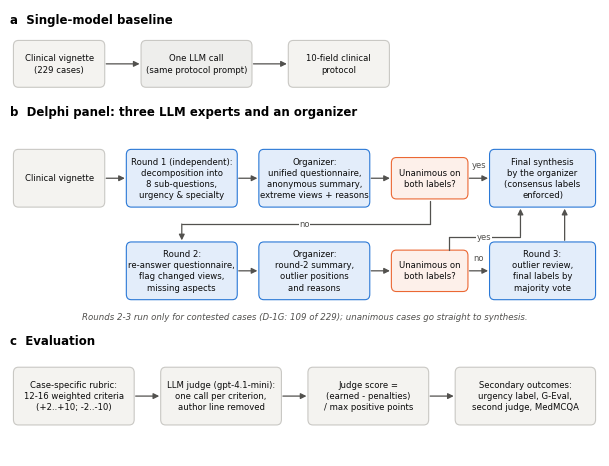

In [2]:
fig, ax = plt.subplots(figsize=(7.6, 5.8))
ax.set_xlim(0, 120)
ax.set_ylim(0, 82)
ax.axis('off')
FS = 6.1

def box(x, y, w, h, text, fc='#f4f3f0', ec='#c9c8c4'):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.3,rounding_size=1.0', fc=fc, ec=ec, lw=0.8))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=FS, color=INK, linespacing=1.3)

def seg(pts, color=MUTED):
    for (x1, y1), (x2, y2) in zip(pts[:-2], pts[1:-1]):
        ax.plot([x1, x2], [y1, y2], color=color, lw=0.9, solid_capstyle='round')
    (x1, y1), (x2, y2) = (pts[-2], pts[-1])
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='-|>', color=color, lw=0.9, shrinkA=0, shrinkB=0))

def lab(x, y, t):
    ax.text(x, y, t, fontsize=6.0, color=MUTED, ha='center', va='center', bbox=dict(fc='white', ec='none', pad=0.4))
BLF, ORF = ('#e3edfa', '#fdf0ea')
ax.text(0, 79.5, 'a  Single-model baseline', fontsize=8.5, fontweight='bold')
box(1, 68, 18, 8, 'Clinical vignette\n(229 cases)')
box(27, 68, 22, 8, 'One LLM call\n(same protocol prompt)', fc='#eeeeec')
box(57, 68, 20, 8, '10-field clinical\nprotocol')
seg([(19.6, 72), (26.4, 72)])
seg([(49.6, 72), (56.4, 72)])
ax.text(0, 62.5, 'b  Delphi panel: three LLM experts and an organizer', fontsize=8.5, fontweight='bold')
box(1, 46, 18, 10, 'Clinical vignette')
box(24, 46, 22, 10, 'Round 1 (independent):\ndecomposition into\n8 sub-questions,\nurgency & specialty', fc=BLF, ec=BLUE)
box(51, 46, 22, 10, 'Organizer:\nunified questionnaire,\nanonymous summary,\nextreme views + reasons', fc=BLF, ec=BLUE)
box(78, 47.5, 15, 7, 'Unanimous on\nboth labels?', fc=ORF, ec=ORANGE)
box(98, 46, 21, 10, 'Final synthesis\nby the organizer\n(consensus labels\nenforced)', fc=BLF, ec=BLUE)
seg([(19.6, 51), (23.4, 51)])
seg([(46.6, 51), (50.4, 51)])
seg([(73.6, 51), (77.4, 51)])
seg([(93.6, 51), (97.4, 51)])
lab(95.5, 53.4, 'yes')
box(24, 29, 22, 10, 'Round 2:\nre-answer questionnaire,\nflag changed views,\nmissing aspects', fc=BLF, ec=BLUE)
box(51, 29, 22, 10, 'Organizer:\nround-2 summary,\noutlier positions\nand reasons', fc=BLF, ec=BLUE)
box(78, 30.5, 15, 7, 'Unanimous on\nboth labels?', fc=ORF, ec=ORANGE)
box(98, 29, 21, 10, 'Round 3:\noutlier review,\nfinal labels by\nmajority vote', fc=BLF, ec=BLUE)
seg([(85.5, 46.9), (85.5, 42.6), (35, 42.6), (35, 39.6)])
lab(60, 42.6, 'no')
seg([(46.6, 34), (50.4, 34)])
seg([(73.6, 34), (77.4, 34)])
seg([(93.6, 34), (97.4, 34)])
lab(95.5, 36.4, 'no')
seg([(89.5, 37.9), (89.5, 40.3), (104, 40.3), (104, 45.4)])
lab(96.5, 40.3, 'yes')
seg([(113, 39.6), (113, 45.4)])
ax.text(60, 25.0, 'Rounds 2-3 run only for contested cases (D-1G: 109 of 229); unanimous cases go straight to synthesis.', fontsize=6.2, color=MUTED, ha='center', style='italic')
ax.text(0, 20.5, 'c  Evaluation', fontsize=8.5, fontweight='bold')
box(1, 6, 24, 10, 'Case-specific rubric:\n12-16 weighted criteria\n(+2..+10; -2..-10)')
box(31, 6, 24, 10, 'LLM judge (gpt-4.1-mini):\none call per criterion,\nauthor line removed')
box(61, 6, 24, 10, 'Judge score =\n(earned - penalties)\n/ max positive points')
box(91, 6, 28, 10, 'Secondary outcomes:\nurgency label, G-Eval,\nsecond judge, MedMCQA')
seg([(25.6, 11), (30.4, 11)])
seg([(55.6, 11), (60.4, 11)])
seg([(85.6, 11), (90.4, 11)])
save(fig, 'Fig1_design.png')


saved figures/Fig2_main.png


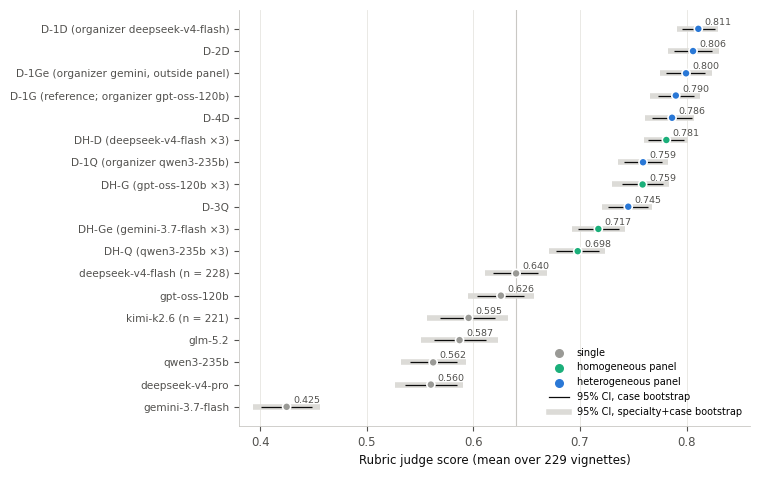

In [3]:
a = T('clinical_system_scores.csv')
name = {'P-base/org-ds': 'D-1D (organizer deepseek-v4-flash)', 'P-base/org-qwen': 'D-1Q (organizer qwen3-235b)', 'P-base/org-gemini': 'D-1Ge (organizer gemini, outside panel)', 'P-base': 'D-1G (reference; organizer gpt-oss-120b)', 'P-weak': 'D-3Q', 'P-mixed': 'D-4D', 'P-strong': 'D-2D', 'homog gpt': 'DH-G (gpt-oss-120b ×3)', 'homog qwen': 'DH-Q (qwen3-235b ×3)', 'homog deepseekv4': 'DH-D (deepseek-v4-flash ×3)', 'homog gemini': 'DH-Ge (gemini-3.7-flash ×3)'}
a['label'] = [name.get(k, arm) for k, arm in zip(a.key, a.arm)]
a['label'] = a['label'].replace({'kimi': 'kimi-k2.6 (n = 221)', 'qwen3-235b-a22b': 'qwen3-235b', 'deepseek-v4-flash': 'deepseek-v4-flash (n = 228)'})
a = a.sort_values('judge_mean')
col = {'single': GREY, 'homogeneous panel': AQUA, 'heterogeneous panel': BLUE}
fig, ax = plt.subplots(figsize=(6.6, 5.4))
y = np.arange(len(a))
ax.axvline(a[a.kind == 'single'].judge_mean.max(), color='#c9c8c4', lw=0.8, zorder=0)
ax.hlines(y, a.ci_domain_lo, a.ci_domain_hi, color='#dcdbd7', lw=4, zorder=1)
ax.hlines(y, a.ci_case_lo, a.ci_case_hi, color=INK, lw=0.9, zorder=2)
ax.scatter(a.judge_mean, y, s=34, c=[col[k] for k in a.kind], zorder=3, edgecolors='white', linewidths=1.2)
for yi, (m, lab) in enumerate(zip(a.judge_mean, a.label)):
    ax.text(m + 0.006, yi + 0.18, f'{m:.3f}', fontsize=6.8, color=MUTED)
ax.set_yticks(y)
ax.set_yticklabels(a.label, fontsize=7.6)
ax.set_xlabel('Rubric judge score (mean over 229 vignettes)')
ax.set_xlim(0.38, 0.86)
ax.grid(axis='x')
ax.set_axisbelow(True)
for k, c in col.items():
    ax.scatter([], [], c=c, s=30, label=k)
ax.plot([], [], color=INK, lw=0.9, label='95% CI, case bootstrap')
ax.plot([], [], color='#dcdbd7', lw=4, label='95% CI, specialty+case bootstrap')
ax.legend(loc='lower right', fontsize=7)
save(fig, 'Fig2_main.png')


saved figures/Fig3_cost_roles.png


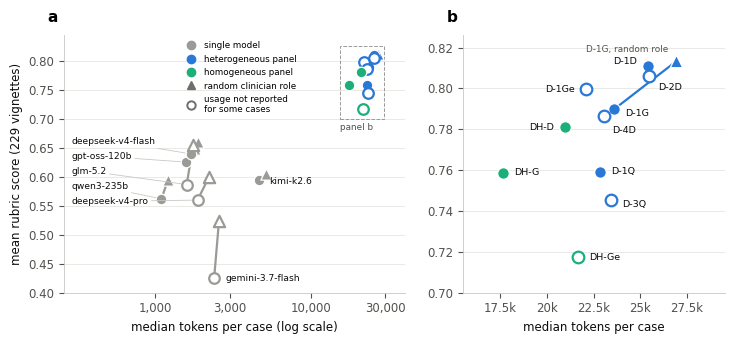

In [4]:
cr = T('token_costs_by_role_configuration.csv')
cr = cr[cr.plot_tokens]
SHORT = {'gpt': 'gpt-oss-120b', 'qwen': 'qwen3-235b', 'deepseekv4': 'deepseek-v4-flash', 'deepseekv4pro': 'deepseek-v4-pro', 'gemini': 'gemini-3.7-flash', 'glm': 'glm-5.2', 'kimi': 'kimi-k2.6', 'P-base': 'D-1G', 'P-base/org-ds': 'D-1D', 'P-base/org-qwen': 'D-1Q', 'P-base/org-gemini': 'D-1Ge', 'P-strong': 'D-2D', 'P-weak': 'D-3Q', 'P-mixed': 'D-4D', 'homog gpt': 'DH-G', 'homog qwen': 'DH-Q', 'homog deepseekv4': 'DH-D', 'homog gemini': 'DH-Ge'}
kind_col = lambda arm: GREY if arm in P.SINGLES else AQUA if arm.startswith('homog') else BLUE
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

def draw_points(ax, s_circle=58, s_tri=66):
    for arm, g in cr.groupby('arm', sort=False):
        c = kind_col(arm)
        g = g.set_index('design')
        if 'randomroles' in g.index:
            ax.plot([g.loc['noroles', 'tokens_median_recorded'], g.loc['randomroles', 'tokens_median_recorded']], [g.loc['noroles', 'score'], g.loc['randomroles', 'score']], color=c, lw=1.6, zorder=2)
        for des, mk in (('noroles', 'o'), ('randomroles', '^')):
            if des not in g.index:
                continue
            full = bool(g.loc[des, 'tokens_complete'])
            ax.scatter(g.loc[des, 'tokens_median_recorded'], g.loc[des, 'score'], marker=mk, s=s_circle if mk == 'o' else s_tri, facecolors=c if full else 'white', edgecolors='white' if full else c, linewidths=0.9 if full else 1.6, zorder=3)
base = cr[cr.design == 'noroles'].set_index('arm')
fig, (axA, axB) = plt.subplots(1, 2, figsize=(7.4, 3.5), gridspec_kw={'width_ratios': [1.3, 1.0]})
draw_points(axA)
axA.set_xscale('log')
axA.set_xlim(260, 40000)
axA.set_ylim(0.4, 0.845)
axA.xaxis.set_major_locator(FixedLocator([1000, 3000, 10000, 30000]))
axA.xaxis.set_minor_locator(NullLocator())
axA.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
axA.set_xlabel('median tokens per case (log scale)')
axA.set_ylabel('mean rubric score (229 vignettes)')
axA.grid(axis='y')
axA.set_axisbelow(True)
col_left = [('deepseekv4', 0.662), ('gpt', 0.636), ('glm', 0.61), ('qwen', 0.584), ('deepseekv4pro', 0.558)]
for arm, yl in col_left:
    axA.annotate(SHORT[arm], (base.loc[arm, 'tokens_median_recorded'], base.loc[arm, 'score']), xytext=(290, yl), textcoords='data', fontsize=6.6, color=INK, va='center', ha='left', arrowprops=dict(arrowstyle='-', color='#c9c8c4', lw=0.6, shrinkA=0, shrinkB=4))
for arm, (dx, dy) in {'kimi': (7, -3), 'gemini': (8, -2)}.items():
    axA.annotate(SHORT[arm], (base.loc[arm, 'tokens_median_recorded'], base.loc[arm, 'score']), xytext=(dx, dy), textcoords='offset points', fontsize=6.6, color=INK, ha='left')
ZX, ZY = ((15500, 29500), (0.7, 0.826))
axA.add_patch(Rectangle((ZX[0], ZY[0]), ZX[1] - ZX[0], ZY[1] - ZY[0], fill=False, ec='#9a9a96', lw=0.7, ls='--', zorder=1))
axA.text(ZX[0], ZY[0] - 0.006, 'panel b', fontsize=6.4, color=MUTED, va='top')
hand = [Line2D([], [], marker='o', ls='', color=GREY, ms=6, label='single model'), Line2D([], [], marker='o', ls='', color=BLUE, ms=6, label='heterogeneous panel'), Line2D([], [], marker='o', ls='', color=AQUA, ms=6, label='homogeneous panel'), Line2D([], [], marker='^', ls='', mfc='#6f6e6a', mec='#6f6e6a', ms=6, label='random clinician role'), Line2D([], [], marker='o', ls='', mfc='white', mec='#6f6e6a', mew=1.4, ms=6, label='usage not reported\nfor some cases')]
axA.legend(handles=hand, loc='upper left', bbox_to_anchor=(0.33, 1.0), fontsize=6.3, handletextpad=0.4, borderaxespad=0.3, labelspacing=0.5)
panel_label(axA, 'a')
draw_points(axB, 70, 80)
axB.set_xlim(*ZX)
axB.set_ylim(*ZY)
axB.xaxis.set_major_locator(FixedLocator([17500, 20000, 22500, 25000, 27500]))
axB.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / 1000:g}k'))
axB.set_xlabel('median tokens per case')
axB.grid(axis='y')
axB.set_axisbelow(True)
lab_off = {'P-base/org-ds': (-8, 3), 'P-strong': (7, -8), 'P-base': (8, -3), 'P-mixed': (6, -10), 'P-base/org-gemini': (-8, 0), 'homog deepseekv4': (-8, 0), 'P-base/org-qwen': (8, 0), 'P-weak': (8, -3), 'homog gpt': (8, 0), 'homog gemini': (8, 0)}
for arm, (dx, dy) in lab_off.items():
    if arm in base.index:
        axB.annotate(SHORT[arm], (base.loc[arm, 'tokens_median_recorded'], base.loc[arm, 'score']), xytext=(dx, dy), textcoords='offset points', fontsize=6.8, color=INK, va='center', ha='left' if dx > 0 else 'right')
rr = cr[(cr.arm == 'P-base') & (cr.design == 'randomroles')].iloc[0]
axB.annotate('D-1G, random role', (rr.tokens_median_recorded, rr.score), xytext=(-6, 7), textcoords='offset points', fontsize=6.4, color=MUTED, ha='right')
panel_label(axB, 'b')
fig.tight_layout(w_pad=1.6)
save(fig, 'Fig3_cost_roles.png')


saved figures/Fig4_mechanism.png


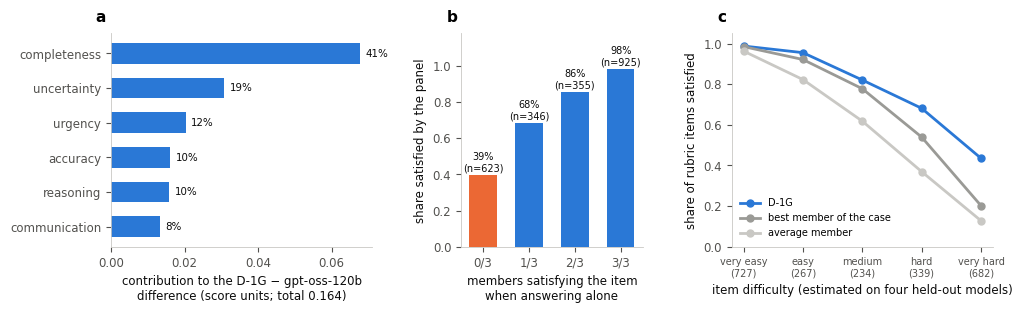

In [5]:
dec = T('criterion_recovery_by_scoring_axis.csv')
gen = T('criterion_recovery_by_successful_members.csv')
dif = T('criterion_recovery_by_difficulty.csv')
fig, axs = plt.subplots(1, 3, figsize=(10.2, 3.2), gridspec_kw={'width_ratios': [1.15, 0.8, 1.15]})
d = dec[dec.vs == 'gpt-oss-120b'].set_index('axis')
order = ['completeness', 'uncertainty', 'urgency', 'accuracy', 'reasoning', 'communication_quality']
d = d.loc[order]
axs[0].barh(range(6), d.contribution, color=BLUE, height=0.6)
for i, (c, s) in enumerate(zip(d.contribution, d.share)):
    axs[0].text(c + 0.0015, i, f'{s:.0%}', va='center', fontsize=7.4, color=INK)
axs[0].set_yticks(range(6))
axs[0].set_yticklabels([o.replace('_quality', '') for o in order])
axs[0].invert_yaxis()
axs[0].set_xlabel('contribution to the D-1G − gpt-oss-120b\ndifference (score units; total 0.164)')
panel_label(axs[0], 'a')
axs[1].bar(gen.k_members, gen.panel_met, color=[ORANGE, BLUE, BLUE, BLUE], width=0.6)
for k, (v, n) in enumerate(zip(gen.panel_met, gen['items'])):
    axs[1].text(k, v + 0.02, f'{v:.0%}\n(n={n})', ha='center', fontsize=7, color=INK)
axs[1].set_xticks(range(4))
axs[1].set_xticklabels(['0/3', '1/3', '2/3', '3/3'])
axs[1].set_xlabel('members satisfying the item\nwhen answering alone')
axs[1].set_ylabel('share satisfied by the panel')
axs[1].set_ylim(0, 1.18)
panel_label(axs[1], 'b')
x = np.arange(len(dif))
axs[2].plot(x, dif.panel, '-o', color=BLUE, lw=2, ms=5, label='D-1G')
axs[2].plot(x, dif.best_member, '-o', color=GREY, lw=2, ms=5, label='best member of the case')
axs[2].plot(x, dif.mean_members, '-o', color='#c9c8c4', lw=2, ms=5, label='average member')
axs[2].set_xticks(x)
axs[2].set_xticklabels([f'{s}\n({n})' for s, n in zip(dif.stratum, dif['items'])], fontsize=7)
axs[2].set_ylabel('share of rubric items satisfied')
axs[2].set_ylim(0, 1.05)
axs[2].set_xlabel('item difficulty (estimated on four held-out models)')
axs[2].legend(fontsize=7, loc='lower left')
panel_label(axs[2], 'c')
fig.tight_layout(w_pad=2.2)
save(fig, 'Fig4_mechanism.png')


saved figures/Fig5_rounds.png


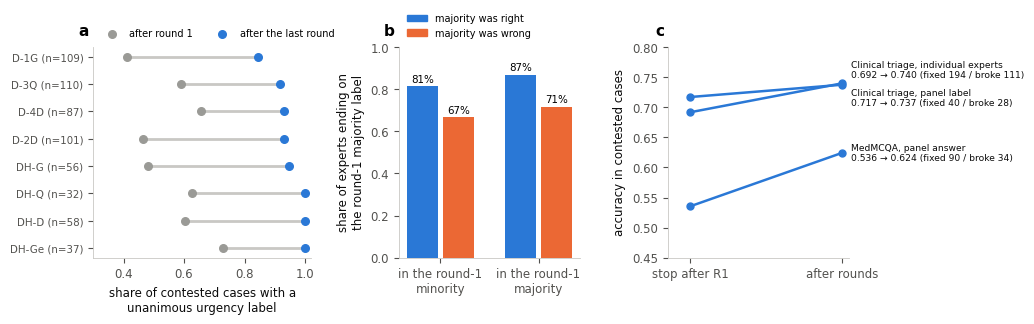

In [6]:
cons = T('round_consensus_changes.csv')
inf = T('panel_member_influence.csv')
ind = T('individual_member_triage_accuracy.csv')
tri = T('triage_accuracy_final_vs_first_round.csv')
mq = T('medmcqa_accuracy_by_round.csv')
fig, axs = plt.subplots(1, 3, figsize=(10.4, 3.3), gridspec_kw={'width_ratios': [1.2, 1.0, 1.0]})
c8 = cons.iloc[:8].copy()
lab8 = {'P-base': 'D-1G', 'P-weak': 'D-3Q', 'P-mixed': 'D-4D', 'P-strong': 'D-2D', 'homog gpt': 'DH-G', 'homog qwen': 'DH-Q', 'homog deepseekv4': 'DH-D', 'homog gemini': 'DH-Ge'}
yy = np.arange(8)
axs[0].hlines(yy, c8.triage_unanimous_R1_in_contested, c8.triage_unanimous_last_in_contested, color='#c9c8c4', lw=2)
axs[0].scatter(c8.triage_unanimous_R1_in_contested, yy, color=GREY, s=30, zorder=3, label='after round 1')
axs[0].scatter(c8.triage_unanimous_last_in_contested, yy, color=BLUE, s=30, zorder=3, label='after the last round')
axs[0].set_yticks(yy)
axs[0].set_yticklabels([f'{lab8[p]} (n={n})' for p, n in zip(c8.panel, c8.contested)], fontsize=7.4)
axs[0].invert_yaxis()
axs[0].set_xlim(0.3, 1.02)
axs[0].set_xlabel('share of contested cases with a\nunanimous urgency label')
axs[0].legend(fontsize=7, loc='lower left', ncol=2, bbox_to_anchor=(0.0, 1.0))
panel_label(axs[0], 'a')
g = inf.set_index(['position', 'maj_correct'])
vals = [g.loc[('minority', True), 'ends_on_majority'], g.loc[('minority', False), 'ends_on_majority'], g.loc[('majority', True), 'ends_on_majority'], g.loc[('majority', False), 'ends_on_majority']]
ns = [g.loc[('minority', True), 'obs'], g.loc[('minority', False), 'obs'], g.loc[('majority', True), 'obs'], g.loc[('majority', False), 'obs']]
xpos = [0, 0.7, 1.9, 2.6]
axs[1].bar(xpos, vals, width=0.6, color=[BLUE, ORANGE, BLUE, ORANGE])
for xp, v, n in zip(xpos, vals, ns):
    axs[1].text(xp, v + 0.02, f'{v:.0%}', ha='center', fontsize=7.4)
axs[1].set_xticks([0.35, 2.25])
axs[1].set_xticklabels(['in the round-1\nminority', 'in the round-1\nmajority'])
axs[1].set_ylabel('share of experts ending on\nthe round-1 majority label')
axs[1].set_ylim(0, 1.0)
axs[1].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
from matplotlib.patches import Patch
axs[1].legend(handles=[Patch(color=BLUE, label='majority was right'), Patch(color=ORANGE, label='majority was wrong')], fontsize=7, loc='lower left', ncol=1, bbox_to_anchor=(0.0, 1.0))
panel_label(axs[1], 'b')
rows = [('Clinical triage,\nindividual experts', ind.iloc[-1].acc_r1, ind.iloc[-1].acc_last, int(ind.iloc[-1].repaired), int(ind.iloc[-1].corrupted)), ('Clinical triage,\npanel label', tri.iloc[-1].acc_r1_plurality, tri.iloc[-1].acc_final, int(tri.iloc[-1].fixed_by_rounds), int(tri.iloc[-1].broken_by_rounds)), ('MedMCQA,\npanel answer', mq.iloc[-1].acc_contested_r1_plurality, mq.iloc[-1].acc_contested_final, int(mq.iloc[-1].fixed_by_rounds), int(mq.iloc[-1].broken_by_rounds))]
offs = [0.022, -0.022, 0.0]
for i, (lab, a0, a1, fx, br) in enumerate(rows):
    axs[2].plot([0, 1], [a0, a1], '-o', color=BLUE if a1 > a0 else GREY, lw=1.8, ms=5)
    axs[2].text(1.06, a1 + offs[i], f"{lab.replace(chr(10), ' ')}\n{a0:.3f} → {a1:.3f} (fixed {fx} / broke {br})", va='center', fontsize=6.6, color=INK)
axs[2].set_xticks([0, 1])
axs[2].set_xticklabels(['stop after R1', 'after rounds'])
axs[2].set_xlim(-0.15, 1.05)
axs[2].set_ylabel('accuracy in contested cases')
axs[2].set_ylim(0.45, 0.8)
panel_label(axs[2], 'c')
fig.tight_layout(w_pad=2.0)
save(fig, 'Fig5_rounds.png')


saved figures/Fig6_medmcqa.png


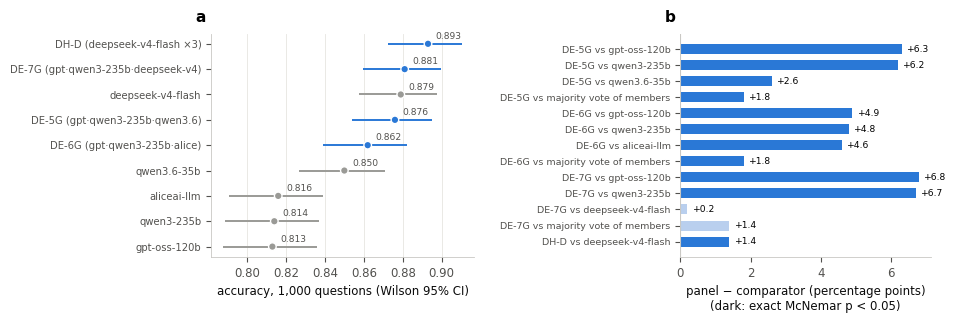

In [7]:
acc = T('medmcqa_accuracy_1000_cases.csv').sort_values('accuracy')
MQ = {'DeepSeek trio (deepseek-v4 ×3)': 'DH-D (deepseek-v4-flash ×3)', 'AC-DeepSeek (gpt·qwen3-235b·deepseek-v4)': 'DE-7G (gpt·qwen3-235b·deepseek-v4)', 'Optimum (gpt·qwen3-235b·qwen3.6)': 'DE-5G (gpt·qwen3-235b·qwen3.6)', 'AC-Alice (gpt·qwen3-235b·alice)': 'DE-6G (gpt·qwen3-235b·alice)'}
acc['system'] = acc.system.replace(MQ)
pv = T('medmcqa_panel_vs_members.csv')
fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.3), gridspec_kw={'width_ratios': [1.05, 1.0]})
y = np.arange(len(acc))
cc = [BLUE if k == 'panel' else GREY for k in acc.kind]
axs[0].hlines(y, acc.ci_lo, acc.ci_hi, color=cc, lw=1.4)
axs[0].scatter(acc.accuracy, y, color=cc, s=30, zorder=3, edgecolors='white', linewidths=1)
axs[0].set_yticks(y)
axs[0].set_yticklabels(acc.system, fontsize=7.2)
for yi, v in zip(y, acc.accuracy):
    axs[0].text(v + 0.004, yi + 0.2, f'{v:.3f}', fontsize=6.6, color=MUTED)
axs[0].set_xlabel('accuracy, 1,000 questions (Wilson 95% CI)')
axs[0].grid(axis='x')
axs[0].set_axisbelow(True)
panel_label(axs[0], 'a')
p = pv[~pv.vs.str.startswith('oracle')].copy()
p['short'] = p.panel.str.split(' ').str[0]
order = ['Optimum', 'AC-Alice', 'AC-DeepSeek', 'DeepSeek']
shortname = {'Optimum': 'DE-5G', 'AC-Alice': 'DE-6G', 'AC-DeepSeek': 'DE-7G', 'DeepSeek': 'DH-D'}
rows = []
for o in order:
    sub = p[p.short == o]
    for _, r in sub.iterrows():
        rows.append((o, r.vs.replace("independent majority of members' single runs", 'majority vote of members'), r.diff_pp, r.p))
yy = np.arange(len(rows))
axs[1].barh(yy, [r[2] for r in rows], color=[BLUE if r[3] < 0.05 else '#b9cfee' for r in rows], height=0.62)
axs[1].axvline(0, color='#c9c8c4', lw=0.8)
axs[1].set_yticks(yy)
axs[1].set_yticklabels([f'{shortname.get(r[0], r[0])} vs {r[1]}' for r in rows], fontsize=6.8)
axs[1].invert_yaxis()
for yi, r in enumerate(rows):
    axs[1].text(r[2] + 0.15 if r[2] >= 0 else r[2] - 0.15, yi, f'{r[2]:+.1f}', va='center', ha='left' if r[2] >= 0 else 'right', fontsize=6.6)
axs[1].set_xlabel('panel − comparator (percentage points)\n(dark: exact McNemar p < 0.05)')
panel_label(axs[1], 'b')
fig.tight_layout(w_pad=2.2)
save(fig, 'Fig6_medmcqa.png')
